In [3]:
!pip install pymoo matplotlib -q

In [4]:
import numpy as np

from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

import matplotlib.pyplot as plt

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [5]:
class SOCAllocationProblem(ElementwiseProblem):

    def __init__(self):
        super().__init__(
            n_var=2,
            n_obj=2,
            xl=np.array([1.0, 1.0]),
            xu=np.array([50.0, 10.0])
        )

    def _evaluate(self, x, out, *args, **kwargs):

        analistas = x[0]
        regimento = x[1]

        # Custo: R$ 100 por analista + R$ 50 por regimento
        f1_custo = (analistas * 100) + (regimento * 50)

        # Tempo de resposta em minutos
        f2_tempo = (200 / analistas) + (50 / regimento)

        out["F"] = [f1_custo, f2_tempo]


print("Problema SOC criado com sucesso!")

Problema SOC criado com sucesso!


In [6]:
res2 = minimize(
    SOCAllocationProblem(),
    NSGA2(pop_size=30),
    termination=('n_gen', 40),
    seed=2
)

print("Otimização SOC concluída com sucesso!")

Otimização SOC concluída com sucesso!


In [7]:
print("RESULTADOS DO EXERCÍCIO 2")
print("=" * 50)

for i in range(len(res2.F)):

    custo = res2.F[i, 0]
    tempo = res2.F[i, 1]

    print(f"Solução {i+1}")
    print(f"Custo: R$ {custo:.2f}")
    print(f"Tempo de resposta: {tempo:.2f} minutos")
    print("-" * 30)

RESULTADOS DO EXERCÍCIO 2
Solução 1
Custo: R$ 150.00
Tempo de resposta: 250.00 minutos
------------------------------
Solução 2
Custo: R$ 5499.86
Tempo de resposta: 9.00 minutos
------------------------------
Solução 3
Custo: R$ 311.52
Tempo de resposta: 119.61 minutos
------------------------------
Solução 4
Custo: R$ 2406.17
Tempo de resposta: 15.50 minutos
------------------------------
Solução 5
Custo: R$ 1951.42
Tempo de resposta: 18.97 minutos
------------------------------
Solução 6
Custo: R$ 257.78
Tempo de resposta: 170.75 minutos
------------------------------
Solução 7
Custo: R$ 477.67
Tempo de resposta: 81.90 minutos
------------------------------
Solução 8
Custo: R$ 4091.70
Tempo de resposta: 10.62 minutos
------------------------------
Solução 9
Custo: R$ 172.22
Tempo de resposta: 216.69 minutos
------------------------------
Solução 10
Custo: R$ 618.54
Tempo de resposta: 68.82 minutos
------------------------------
Solução 11
Custo: R$ 3365.80
Tempo de resposta: 12.16 mi

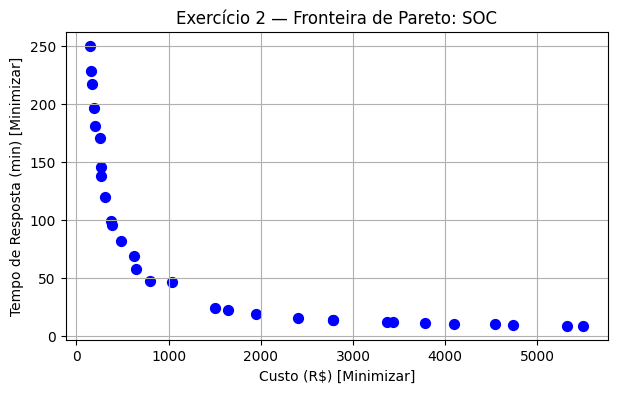

In [8]:
plt.figure(figsize=(7, 4))

plt.scatter(
    res2.F[:, 0],
    res2.F[:, 1],
    color='blue',
    s=50
)

plt.title("Exercício 2 — Fronteira de Pareto: SOC")
plt.xlabel("Custo (R$) [Minimizar]")
plt.ylabel("Tempo de Resposta (min) [Minimizar]")

plt.grid(True)
plt.show()